# 02 · Data Cleaning

Notebook 01 turned up a few problems: a ramp-up period at the start, fuel and misc lines with
absurd quantities, zero-value rows, and duplicate coupons. This notebook fixes those and produces
the tables the modelling notebooks will use:

| Output | What it is |
|---|---|
| `transactions_clean.parquet` | one row per line item, with discount and display/mailer flags |
| `commodity_week.parquet` | sales, discount depth and promo share per commodity per week (input for the baseline model) |
| `campaigns.parquet` | campaign info with duration and households targeted |
| `campaign_households.parquet` | which household received which campaign |
| `coupons_clean.parquet` | coupon → product mapping, de-duplicated |

I keep a log of how many rows and how much sales each step removes, so the cleaning is easy to audit.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

def load(name, **kw):
    df = pd.read_csv(RAW / f"{name}.csv", **kw)
    df.columns = df.columns.str.lower()
    return df

## Settings

All the cleaning decisions live here so they're easy to change and easy to explain.

In [2]:
FIRST_WEEK = 17    # weeks 1–16 are the ramp-up period seen in notebook 01
LAST_WEEK = 101    # week 102 is incomplete

# not real grocery purchases: fuel, misc transactions, coupon lines
EXCLUDE_DEPARTMENTS = ["KIOSK-GAS", "MISC SALES TRAN", "MISC. TRANS."]
EXCLUDE_COMMODITIES = ["COUPON/MISC ITEMS"]

# a commodity needs this much data to be worth modelling at the weekly level
MIN_WEEKS_PRESENT = 80          # out of 85 weeks
MIN_UNITS_PER_WEEK = 20         # median weekly units

## Load raw data

In [3]:
transactions = load("transaction_data")
products = load("product")

for col in ["department", "commodity_desc", "sub_commodity_desc", "brand"]:
    products[col] = products[col].astype(str).str.strip()

print(f"{len(transactions):,} transaction rows, {len(products):,} products")

2,595,732 transaction rows, 92,353 products


In [4]:
log = []

def log_step(step, df):
    log.append({"step": step, "rows": len(df), "sales_value": df["sales_value"].sum()})
    print(f"{step:<45} {len(df):>12,} rows   {df['sales_value'].sum():>14,.0f} sales")

log_step("raw", transactions)

raw                                              2,595,732 rows        8,057,463 sales


## Step 1 · Remove non-grocery lines

Before dropping anything, here's what the excluded departments actually look like.

In [5]:
tx = transactions.merge(
    products[["product_id", "department", "commodity_desc", "sub_commodity_desc", "brand"]],
    on="product_id", how="left",
)

excluded_mask = tx["department"].isin(EXCLUDE_DEPARTMENTS) | tx["commodity_desc"].isin(EXCLUDE_COMMODITIES)

(tx.loc[excluded_mask]
   .groupby(["department", "commodity_desc"])
   .agg(rows=("quantity", "size"), max_quantity=("quantity", "max"), sales=("sales_value", "sum"))
   .sort_values("rows", ascending=False))

,,rows,max_quantity,sales
department,commodity_desc,,,
KIOSK-GAS,COUPON/MISC ITEMS,20271,89638,"514,685.72"
MISC SALES TRAN,COUPON/MISC ITEMS,6050,85055,"119,960.04"
MISC. TRANS.,NO COMMODITY DESCRIPTION,2351,30,"10,678.69"
KIOSK-GAS,FUEL,1788,30080,"29,536.56"
GROCERY,COUPON/MISC ITEMS,1392,35,"4,564.33"
COSMETICS,COUPON/MISC ITEMS,48,2,313.24
GM MERCH EXP,COUPON/MISC ITEMS,47,2,92.06
CNTRL/STORE SUP,COUPON/MISC ITEMS,21,3,49.05
DRUG GM,COUPON/MISC ITEMS,13,4,185.20


In [6]:
missing = set(EXCLUDE_DEPARTMENTS) - set(tx["department"].unique())
if missing:
    print("Not found in data (check spelling):", missing)

tx = tx.loc[~excluded_mask & tx["department"].notna()].copy()
log_step("drop fuel / misc / coupon lines", tx)

drop fuel / misc / coupon lines                  2,563,744 rows        7,377,369 sales


## Step 2 · Remove zero-value rows

Rows with zero quantity or zero sales value don't represent a real sale.
There are no negative sales values in this dataset (notebook 01), so returns aren't an issue.

In [7]:
tx = tx.loc[(tx["quantity"] > 0) & (tx["sales_value"] > 0)].copy()
log_step("drop zero quantity / sales", tx)

drop zero quantity / sales                       2,545,038 rows        7,377,350 sales


## Step 3 · Keep the stable period

In [8]:
tx = tx.loc[tx["week_no"].between(FIRST_WEEK, LAST_WEEK)].copy()
log_step(f"keep weeks {FIRST_WEEK}–{LAST_WEEK}", tx)

keep weeks 17–101                                2,325,819 rows        6,740,663 sales


## Step 4 · Discount columns

The raw discounts are negative numbers. I turn them into positive amounts and work out the list price.

- `gross_value` = what the item would have cost without discounts
- `discount_pct` = retail (loyalty) discount as % of gross value

In [9]:
tx["retail_disc_amt"] = -tx["retail_disc"].clip(upper=0)
tx["coupon_disc_amt"] = -tx["coupon_disc"].clip(upper=0) - tx["coupon_match_disc"].clip(upper=0)
tx["gross_value"] = tx["sales_value"] + tx["retail_disc_amt"] + tx["coupon_disc_amt"]

tx["discount_pct"] = (tx["retail_disc_amt"] / tx["gross_value"] * 100).clip(0, 100)
tx["on_discount"] = tx["retail_disc_amt"] > 0
tx["used_coupon"] = tx["coupon_disc_amt"] > 0

tx["unit_price_paid"] = tx["sales_value"] / tx["quantity"]
tx["unit_list_price"] = tx["gross_value"] / tx["quantity"]

tx[["sales_value", "retail_disc_amt", "coupon_disc_amt", "gross_value", "discount_pct"]].describe()

,sales_value,retail_disc_amt,coupon_disc_amt,gross_value,discount_pct
count,"2,325,819.00","2,325,819.00","2,325,819.00","2,325,819.00","2,325,819.00"
mean,2.90,0.53,0.02,3.45,13.24
std,3.16,1.25,0.19,3.76,16.65
min,0.01,-0.00,-0.00,0.01,-0.00
25%,1.29,-0.00,-0.00,1.59,-0.00
50%,2.00,0.00,0.00,2.59,0.00
75%,3.39,0.65,-0.00,3.99,24.62
max,631.80,180.00,55.93,631.80,99.80


In [10]:
# a discount of 90%+ is usually a data glitch or a free item, worth knowing how common it is
extreme = tx["discount_pct"] >= 90
print(f"lines with 90%+ discount: {extreme.sum():,} ({extreme.mean():.2%})")

lines with 90%+ discount: 85 (0.00%)


## Step 5 · Display and mailer flags from `causal_data`

`causal_data` has one row per product × store × week that had some in-store promotion.
It's 36 million rows, so instead of loading it all I read it in chunks and keep only the
product/store/week combinations that actually appear in the transactions.

A missing row means the product wasn't on display or in the mailer that week.

In [11]:
causal_path = RAW / "causal_data.csv"
header = pd.read_csv(causal_path, nrows=0).columns
dtypes = {c: ("int32" if c.lower() in {"product_id", "store_id"} else
              "int16" if c.lower() == "week_no" else "string")
          for c in header}

keys = tx[["product_id", "store_id", "week_no"]].drop_duplicates()
keys = keys.astype({"product_id": "int32", "store_id": "int32", "week_no": "int16"})

matched, causal_weeks = [], set()
for chunk in pd.read_csv(causal_path, chunksize=2_000_000, dtype=dtypes):
    chunk.columns = chunk.columns.str.lower()
    causal_weeks.update(chunk["week_no"].unique().tolist())
    matched.append(chunk.merge(keys, on=["product_id", "store_id", "week_no"], how="inner"))

causal = pd.concat(matched, ignore_index=True).drop_duplicates(["product_id", "store_id", "week_no"])
causal["on_display"] = causal["display"].fillna("0") != "0"
causal["in_mailer"] = causal["mailer"].fillna("0") != "0"

print(f"matched {len(causal):,} product-store-weeks; causal data covers {len(causal_weeks)} weeks")

matched 449,067 product-store-weeks; causal data covers 93 weeks


In [12]:
tx = tx.astype({"product_id": "int32", "store_id": "int32", "week_no": "int16"}).merge(
    causal[["product_id", "store_id", "week_no", "display", "mailer", "on_display", "in_mailer"]],
    on=["product_id", "store_id", "week_no"], how="left",
)
tx["on_display"] = tx["on_display"].astype("boolean").fillna(False).astype(bool)
tx["in_mailer"] = tx["in_mailer"].astype("boolean").fillna(False).astype(bool)

# weeks with no causal data at all: flags are unknown, not False
tx["causal_available"] = tx["week_no"].isin(causal_weeks)

tx.groupby("causal_available")[["on_display", "in_mailer", "on_discount"]].mean()

,on_display,in_mailer,on_discount
causal_available,,,
True,0.11,0.17,0.50


## Step 6 · Tidy types and save the line-item table

In [13]:
tx = tx.drop(columns=["retail_disc", "coupon_disc", "coupon_match_disc"])

for col in ["department", "commodity_desc", "sub_commodity_desc", "brand", "display", "mailer"]:
    tx[col] = tx[col].astype("category")

tx = tx.astype({"household_key": "int32", "day": "int16", "quantity": "int32"})

print(f"{len(tx):,} rows, {tx.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
tx.to_parquet(PROCESSED / "transactions_clean.parquet", index=False)
tx.head()

2,325,819 rows, 244 MB


,household_key,basket_id,day,product_id,quantity,sales_value,store_id,trans_time,week_no,department,commodity_desc,sub_commodity_desc,brand,retail_disc_amt,coupon_disc_amt,gross_value,discount_pct,on_discount,used_coupon,unit_price_paid,unit_list_price,display,mailer,on_display,in_mailer,causal_available
0,1423,28306132327,111,983673,1,1.49,408,21,17,GROCERY,FLUID MILK PRODUCTS,MISCELLANEOUS MILK,National,-0.00,-0.00,1.49,-0.00,False,False,1.49,1.49,<NA>,<NA>,False,False,True
1,232,28306250387,111,831536,2,1.76,361,24,17,GROCERY,FRZN MEAT/MEAT DINNERS,SS ECONOMY ENTREES/DINNERS ALL,National,0.24,-0.00,2.00,12.00,True,False,0.88,1.00,<NA>,<NA>,False,False,True
2,232,28306250387,111,844023,2,1.76,361,24,17,GROCERY,FRZN MEAT/MEAT DINNERS,SS ECONOMY ENTREES/DINNERS ALL,National,0.24,-0.00,2.00,12.00,True,False,0.88,1.00,<NA>,<NA>,False,False,True
3,232,28306250387,111,920239,1,2.42,361,24,17,GROCERY,CONVENIENT BRKFST/WHLSM SNACKS,TOASTER PASTRIES,Private,0.17,-0.00,2.59,6.56,True,False,2.42,2.59,<NA>,<NA>,False,False,True
4,232,28306250387,111,1014424,8,1.44,361,24,17,GROCERY,CRACKERS/MISC BKD FD,VENDING SIZE/SNGL SERVE CRACKE,Private,0.16,-0.00,1.60,10.00,True,False,0.18,0.20,<NA>,<NA>,False,False,True


## Cleaning log

In [14]:
log_df = pd.DataFrame(log)
log_df["rows_removed"] = -log_df["rows"].diff()
log_df["% rows kept"] = log_df["rows"] / log_df["rows"].iloc[0] * 100
log_df["% sales kept"] = log_df["sales_value"] / log_df["sales_value"].iloc[0] * 100
log_df

,step,rows,sales_value,rows_removed,% rows kept,% sales kept
0,raw,2595732,"8,057,463.08",NaN,100.00,100.00
1,drop fuel / misc / coupon lines,2563744,"7,377,369.27","31,988.00",98.77,91.56
2,drop zero quantity / sales,2545038,"7,377,350.09","18,706.00",98.05,91.56
3,keep weeks 17–101,2325819,"6,740,663.48","219,219.00",89.60,83.66


## Commodity × week table

This is the main input for the baseline and promo-response models. Each row is one commodity
(e.g. *SOFT DRINKS*, *CHEESE*) in one week.

The promo variables are:

- `avg_discount_pct` — retail discount as % of gross value, weighted by sales (the "discount depth")
- `share_units_on_discount` — how much of the volume was sold on discount
- `share_display` / `share_mailer` — share of sales value from products on display / in the mailer

In [15]:
tx["display_value"] = tx["sales_value"] * tx["on_display"]
tx["mailer_value"] = tx["sales_value"] * tx["in_mailer"]
tx["units_on_discount"] = tx["quantity"] * tx["on_discount"]

cw = (
    tx.groupby(["department", "commodity_desc", "week_no"], observed=True)
      .agg(
          units=("quantity", "sum"),
          units_on_discount=("units_on_discount", "sum"),
          sales_value=("sales_value", "sum"),
          gross_value=("gross_value", "sum"),
          retail_disc_amt=("retail_disc_amt", "sum"),
          coupon_disc_amt=("coupon_disc_amt", "sum"),
          display_value=("display_value", "sum"),
          mailer_value=("mailer_value", "sum"),
          households=("household_key", "nunique"),
          baskets=("basket_id", "nunique"),
          products=("product_id", "nunique"),
      )
      .reset_index()
)

cw["avg_discount_pct"] = cw["retail_disc_amt"] / cw["gross_value"] * 100
cw["share_units_on_discount"] = cw["units_on_discount"] / cw["units"]
cw["share_display"] = cw["display_value"] / cw["sales_value"]
cw["share_mailer"] = cw["mailer_value"] / cw["sales_value"]
cw["avg_price_paid"] = cw["sales_value"] / cw["units"]
cw["avg_list_price"] = cw["gross_value"] / cw["units"]
cw["causal_available"] = cw["week_no"].isin(causal_weeks)

print(f"{cw['commodity_desc'].nunique():,} commodities, {len(cw):,} commodity-weeks")

304 commodities, 23,646 commodity-weeks


Many commodities sell only a handful of units a week, which is too noisy to model.
I keep the ones that sell every week (or nearly) with reasonable volume.

In [16]:
coverage = cw.groupby("commodity_desc", observed=True).agg(
    weeks_present=("week_no", "nunique"),
    median_units=("units", "median"),
    total_sales=("sales_value", "sum"),
    avg_discount_pct=("avg_discount_pct", "mean"),
)
keep = coverage.query("weeks_present >= @MIN_WEEKS_PRESENT and median_units >= @MIN_UNITS_PER_WEEK").index

print(f"keeping {len(keep)} of {len(coverage)} commodities, "
      f"covering {coverage.loc[keep, 'total_sales'].sum() / coverage['total_sales'].sum():.1%} of sales")

coverage.loc[keep].sort_values("total_sales", ascending=False).head(15)

keeping 184 of 304 commodities, covering 95.2% of sales


,weeks_present,median_units,total_sales,avg_discount_pct
commodity_desc,,,,
SOFT DRINKS,85,"1,592.00","295,365.07",21.92
BEEF,85,699.00,"282,765.89",17.21
FLUID MILK PRODUCTS,85,"1,119.00","188,702.91",15.80
CHEESE,85,"1,015.00","174,150.52",20.52
FRZN MEAT/MEAT DINNERS,85,852.00,"147,604.43",21.72
BAG SNACKS,85,841.00,"135,182.28",11.65
FROZEN PIZZA,85,705.00,"134,003.96",16.66
BAKED BREAD/BUNS/ROLLS,85,"1,068.00","133,259.23",20.29
BEERS/ALES,85,205.00,"132,667.35",0.07


In [17]:
cw_model = cw.loc[cw["commodity_desc"].isin(keep)].copy()
cw_model["department"] = cw_model["department"].astype(str)
cw_model["commodity_desc"] = cw_model["commodity_desc"].astype(str)

cw_model.to_parquet(PROCESSED / "commodity_week.parquet", index=False)
print(f"saved {len(cw_model):,} rows")

saved 16,119 rows


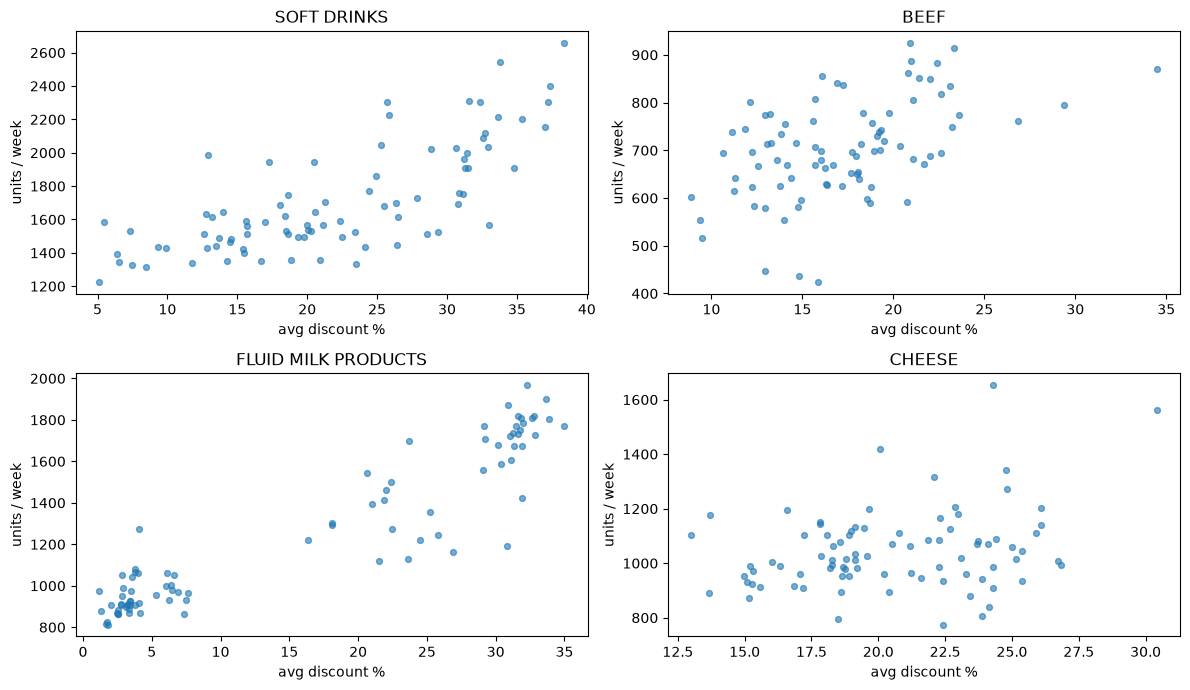

In [18]:
# quick sanity check: does discount depth move with volume? (not causal, just a first look)
top = coverage.loc[keep].nlargest(4, "total_sales").index

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, name in zip(axes.flat, top):
    d = cw_model.loc[cw_model["commodity_desc"] == name]
    ax.scatter(d["avg_discount_pct"], d["units"], alpha=0.6, s=18)
    ax.set_title(name)
    ax.set_xlabel("avg discount %")
    ax.set_ylabel("units / week")
plt.tight_layout()
plt.savefig(FIGURES / "02_discount_vs_units.png", dpi=150)
plt.show()

## Campaign and coupon tables

These are used later for the uplift model.

In [19]:
campaign_desc = load("campaign_desc")
campaign_table = load("campaign_table")
coupons = load("coupon")
coupon_redempt = load("coupon_redempt")

campaigns = (
    campaign_desc
    .rename(columns={"description": "campaign_type"})
    .assign(
        duration_days=lambda d: d["end_day"] - d["start_day"] + 1,
        start_week=lambda d: d["start_day"] // 7 + 1,
        end_week=lambda d: d["end_day"] // 7 + 1,
    )
    .merge(campaign_table.groupby("campaign")["household_key"].nunique().rename("households_targeted"),
           on="campaign", how="left")
    .sort_values("start_day")
    .reset_index(drop=True)
)

campaign_households = (
    campaign_table.rename(columns={"description": "campaign_type"})
    .drop_duplicates(["household_key", "campaign"])
)

coupons_before = len(coupons)
coupons = coupons.drop_duplicates()
print(f"coupons: removed {coupons_before - len(coupons):,} duplicate rows")

campaigns.to_parquet(PROCESSED / "campaigns.parquet", index=False)
campaign_households.to_parquet(PROCESSED / "campaign_households.parquet", index=False)
coupons.to_parquet(PROCESSED / "coupons_clean.parquet", index=False)
coupon_redempt.to_parquet(PROCESSED / "coupon_redemptions.parquet", index=False)

campaigns

coupons: removed 5,164 duplicate rows


,campaign_type,campaign,start_day,end_day,duration_days,start_week,end_week,households_targeted
0,TypeA,26,224,264,41,33,38,332
1,TypeC,27,237,300,64,34,43,12
2,TypeB,28,259,320,62,38,46,17
3,TypeB,29,281,334,54,41,48,118
4,TypeA,30,323,369,47,47,53,361
5,TypeB,1,346,383,38,50,55,13
6,TypeB,2,351,383,33,51,55,48
7,TypeC,3,356,412,57,51,59,12
8,TypeB,4,372,404,33,54,58,81
9,TypeB,5,377,411,35,54,59,166


## Outputs

In [20]:
pd.DataFrame(
    [{"file": p.name, "MB": p.stat().st_size / 1e6} for p in sorted(PROCESSED.glob("*.parquet"))]
)

,file,MB
0,campaign_households.parquet,0.02
1,campaigns.parquet,0.01
2,commodity_week.parquet,1.22
3,coupon_redemptions.parquet,0.02
4,coupons_clean.parquet,0.54
5,products.parquet,1.24
6,transactions.parquet,20.54
7,transactions_clean.parquet,42.00


## Notes for the next notebook

_Fill in after running._

- Rows and sales kept after cleaning:
- Number of commodities kept for modelling:
- Anything odd in the discount vs. units plots: